# Classification — Part A

## Machine Learning Capstone Project

### Objective

The objective of this classification task is to predict the Electric Vehicle Type of a vehicle based on its available vehicle, technical, manufacturer, and
geographic characteristics.

The target variable is:

Electric Vehicle Type

The two target classes are:

- Battery Electric Vehicle (BEV)
- Plug-in Hybrid Electric Vehicle (PHEV)

### Classification Algorithms — Part A

The following five classification algorithms will be implemented:

1. Logistic Regression
2. K-Nearest Neighbors (KNN)
3. Gaussian Naive Bayes
4. Decision Tree Classifier
5. Support Vector Machine (SVM)

### Evaluation

The models will be evaluated using:

- Accuracy
- Precision
- Recall
- Weighted F1-score
- Confusion Matrix

The models will use the same preprocessed dataset and the same train-test
split to ensure a fair comparison.

2. Dataset Loading
The dataset is loaded using Pandas and stored in a DataFrame named df.

At this stage, the raw dataset is loaded without applying any preprocessing, encoding, scaling, or feature transformations.

The first few records are displayed to understand the structure and contents of the dataset.

In [1]:
import pandas as pd
import numpy as np

In [3]:
df = pd.read_csv("../data/Electric_Vehicle_Population_Data.csv")
df.head()

,VIN (1-10),County,City,State,Postal Code,Model Year,Make,Model,Electric Vehicle Type,Clean Alternative Fuel Vehicle (CAFV) Eligibility,Electric Range,Legislative District,DOL Vehicle ID,Vehicle Location,Electric Utility,2020 GEOID
0,5YJ3E1EA5L,Yakima,Yakima,WA,98908.0,2020,TESLA,MODEL 3,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,266.0,14.0,102765120,POINT (-120.60272 46.59656),PACIFICORP,5.307700e+10
1,5YJ3E1EA9K,Thurston,Olympia,WA,98502.0,2019,TESLA,MODEL 3,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,220.0,22.0,326796641,POINT (-122.92018 47.04575),PUGET SOUND ENERGY INC,5.306701e+10
2,5YJSA1H22F,Kitsap,Kingston,WA,98346.0,2015,TESLA,MODEL S,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,208.0,23.0,166294418,POINT (-122.4977 47.79802),PUGET SOUND ENERGY INC,5.303509e+10
3,KM8K33AG7L,King,Seattle,WA,98107.0,2020,HYUNDAI,KONA,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,258.0,43.0,127090015,POINT (-122.38591 47.67597),CITY OF SEATTLE - (WA)|CITY OF TACOMA - (WA),5.303300e+10
4,5YJ3E1EB1K,Yakima,Yakima,WA,98902.0,2019,TESLA,MODEL 3,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,220.0,14.0,272512824,POINT (-120.51904 46.59782),PACIFICORP,5.307700e+10


## 3. Dataset Audit

A dataset audit is performed before exploratory analysis and preprocessing.

The audit examines:

- Dataset dimensions
- Column names
- Data types
- Missing values
- Duplicate records
- Target-class distribution

This helps identify data-quality issues and determine the appropriate preprocessing and visualization strategies for the classification task.

In [4]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

Dataset Shape: (294193, 16)

Column Names:
['VIN (1-10)', 'County', 'City', 'State', 'Postal Code', 'Model Year', 'Make', 'Model', 'Electric Vehicle Type', 'Clean Alternative Fuel Vehicle (CAFV) Eligibility', 'Electric Range', 'Legislative District', 'DOL Vehicle ID', 'Vehicle Location', 'Electric Utility', '2020 GEOID']

Data Types:
VIN (1-10)                                            object
County                                                object
City                                                  object
State                                                 object
Postal Code                                          float64
Model Year                                             int64
Make                                                  object
Model                                                 object
Electric Vehicle Type                                 object
Clean Alternative Fuel Vehicle (CAFV) Eligibility     object
Electric Range                                       f

4.1 Feature Distribution Plots¶
Feature distributions are examined to understand the characteristics of the dataset before preprocessing and model training.

Histograms are used for numerical features, while count plots are used for categorical features. High-cardinality categorical features are visualized using their most frequent categories to maintain readability.

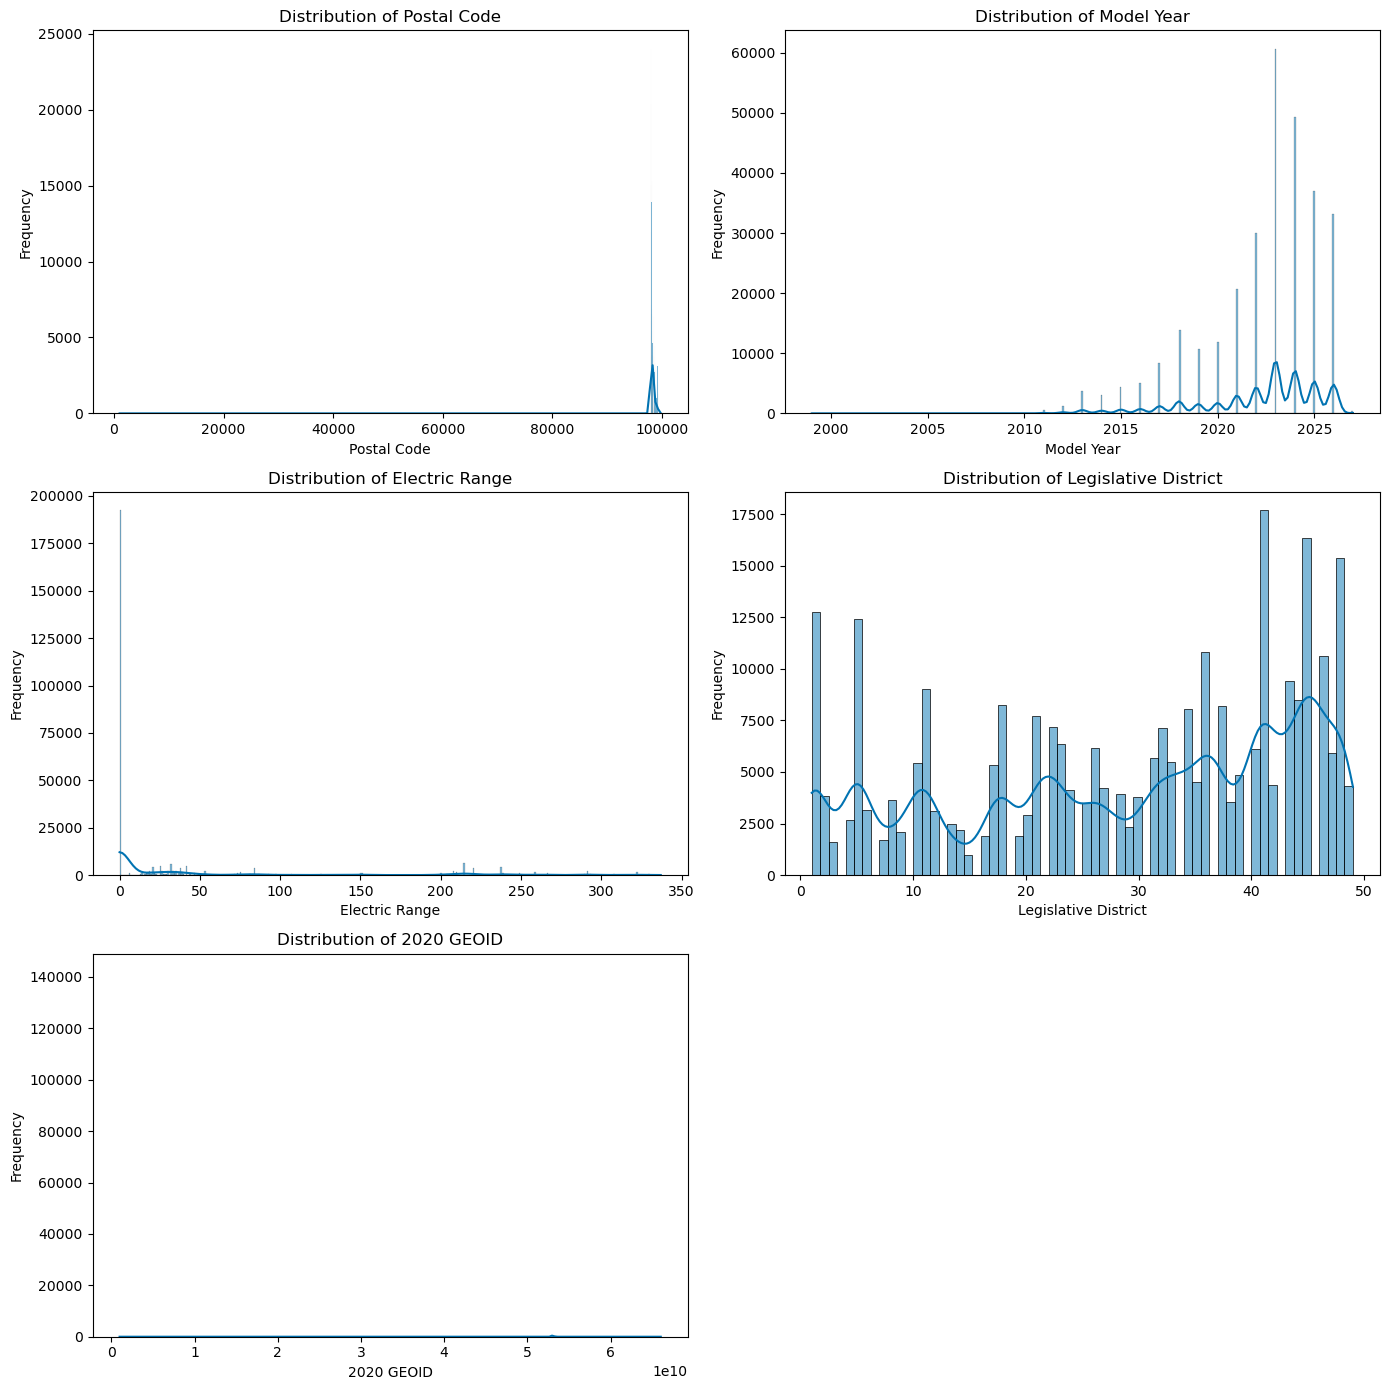

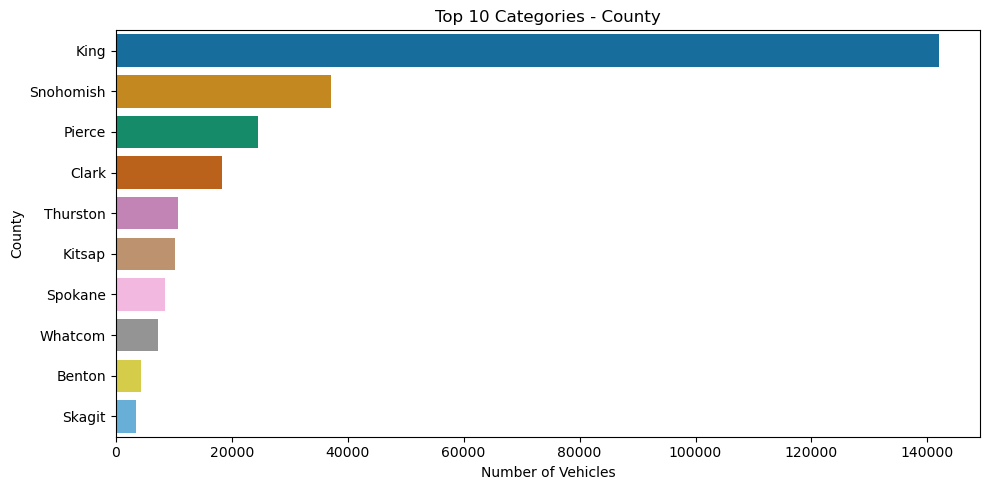

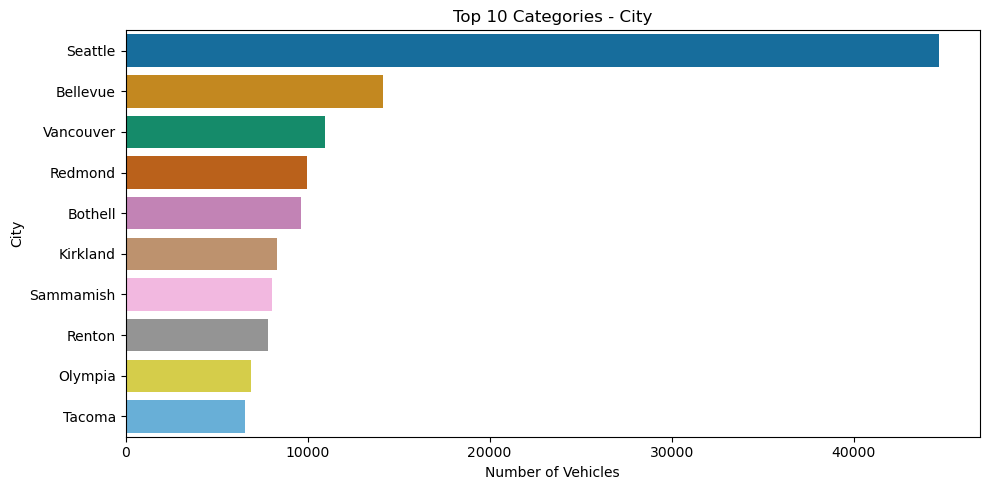

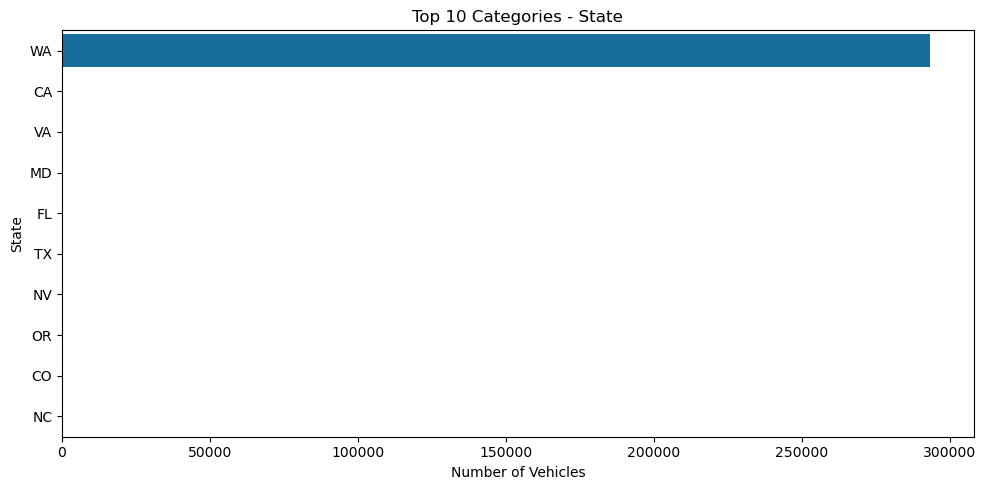

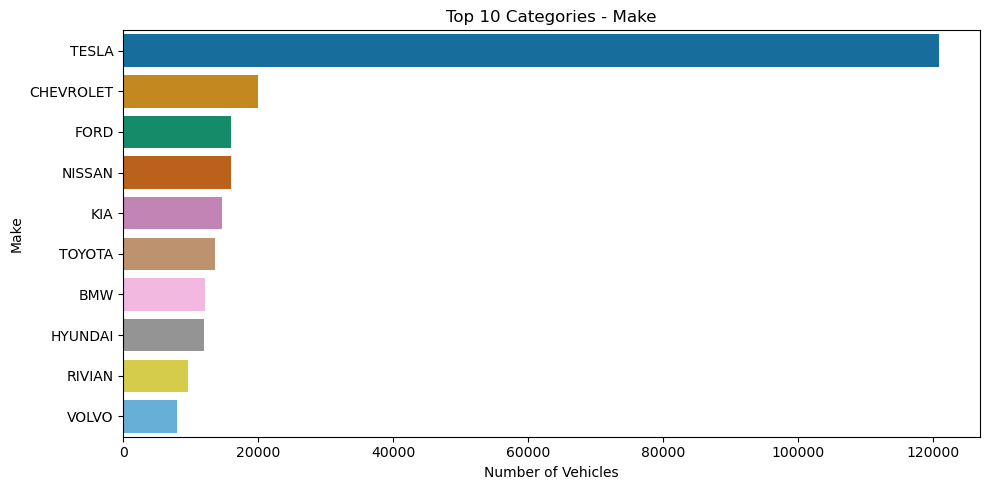

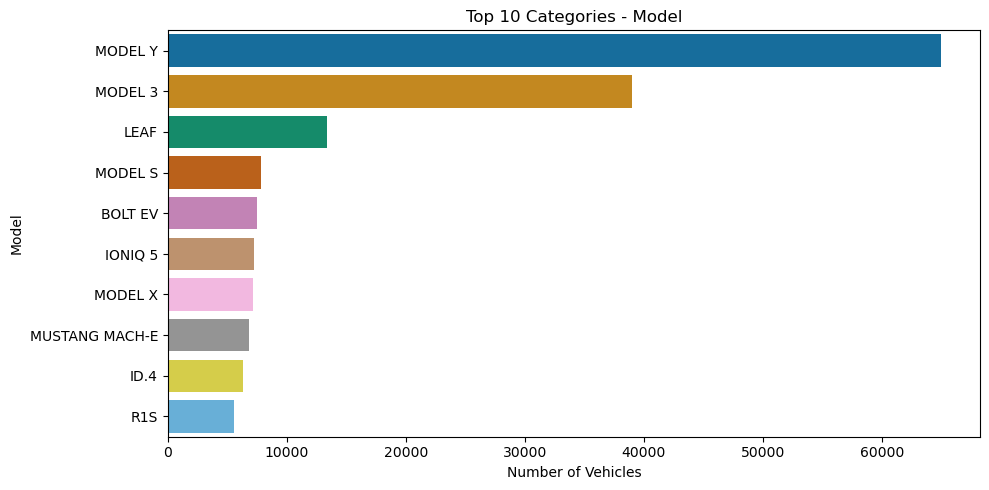

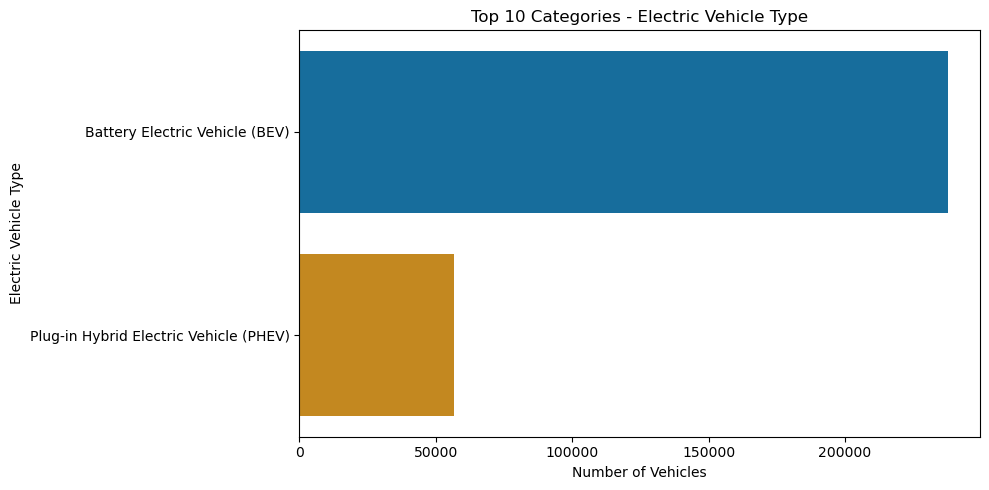

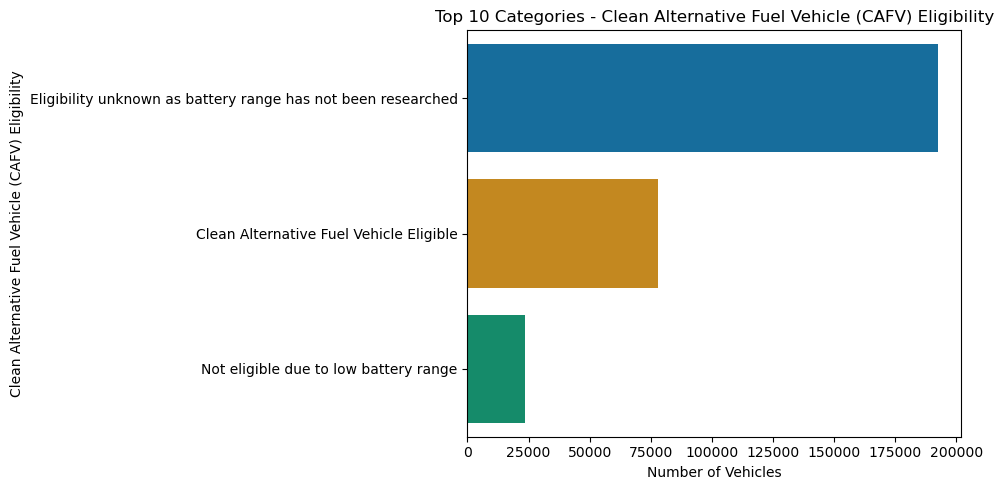

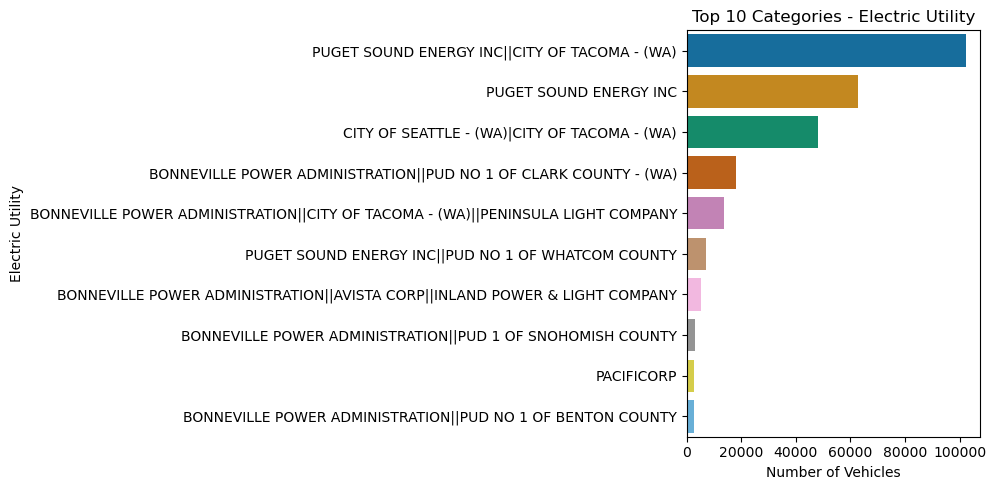

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Colorblind-friendly palette
sns.set_palette("colorblind")

# Numerical features
numerical_features = [
    "Postal Code",
    "Model Year",
    "Electric Range",
    "Legislative District",
    "2020 GEOID"
]

# Plot numerical feature distributions
fig, axes = plt.subplots(3, 2, figsize=(14, 14))
axes = axes.flatten()

for i, column in enumerate(numerical_features):
    sns.histplot(data=df, x=column, kde=True, ax=axes[i])
    axes[i].set_title(f"Distribution of {column}")
    axes[i].set_xlabel(column)
    axes[i].set_ylabel("Frequency")

# Remove unused subplot
axes[-1].remove()

plt.tight_layout()
plt.show()


# Categorical features
categorical_features = [
    "County",
    "City",
    "State",
    "Make",
    "Model",
    "Electric Vehicle Type",
    "Clean Alternative Fuel Vehicle (CAFV) Eligibility",
    "Electric Utility"
]

# Plot top categories for categorical features
for column in categorical_features:
    plt.figure(figsize=(10, 5))
    
    top_categories = df[column].value_counts().head(10)
    
    sns.barplot(
        x=top_categories.values,
        y=top_categories.index
    )
    
    plt.title(f"Top 10 Categories - {column}")
    plt.xlabel("Number of Vehicles")
    plt.ylabel(column)
    plt.tight_layout()
    plt.show()

## 4.2 Target Distribution

The distribution of the target variable is visualized to examine the proportion of each vehicle type in the dataset.

The target variable is `Electric Vehicle Type`, which contains two classes:

- Battery Electric Vehicle (BEV)
- Plug-in Hybrid Electric Vehicle (PHEV)

Understanding the class distribution is important because class imbalance can affect the interpretation of classification performance.

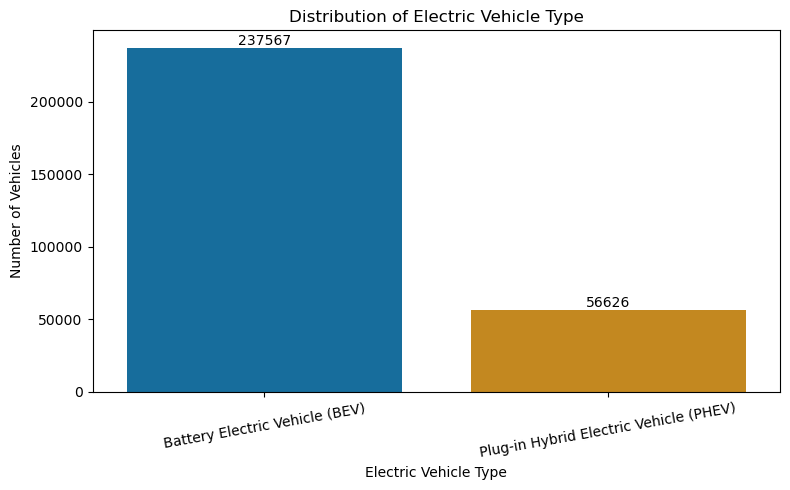

,Percentage
Battery Electric Vehicle (BEV),80.75
Plug-in Hybrid Electric Vehicle (PHEV),19.25


In [6]:
# Target class distribution

target = "Electric Vehicle Type"

plt.figure(figsize=(8, 5))

ax = sns.countplot(data=df, x=target)

plt.title("Distribution of Electric Vehicle Type")
plt.xlabel("Electric Vehicle Type")
plt.ylabel("Number of Vehicles")

# Add count labels
for container in ax.containers:
    ax.bar_label(container)

plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

# Display percentages
target_distribution = (
    df[target]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .to_frame("Percentage")
)

display(target_distribution)

### Observation

The target distribution shows that Battery Electric Vehicles (BEVs) form the majority class, while Plug-in Hybrid Electric Vehicles (PHEVs) form the minority class.

Therefore, the target variable is moderately imbalanced. Model performance should not be judged using accuracy alone; weighted F1-score and the confusion matrix will also be considered during model evaluation.

4.3 Correlation Analysis
A correlation heatmap is used to examine the relationships between numerical features in the dataset.

Correlation values range from -1 to +1:

Values close to +1 indicate a strong positive relationship.
Values close to -1 indicate a strong negative relationship.
Values close to 0 indicate a weak or no linear relationship.
The heatmap helps identify highly correlated features and possible redundancy before model training.

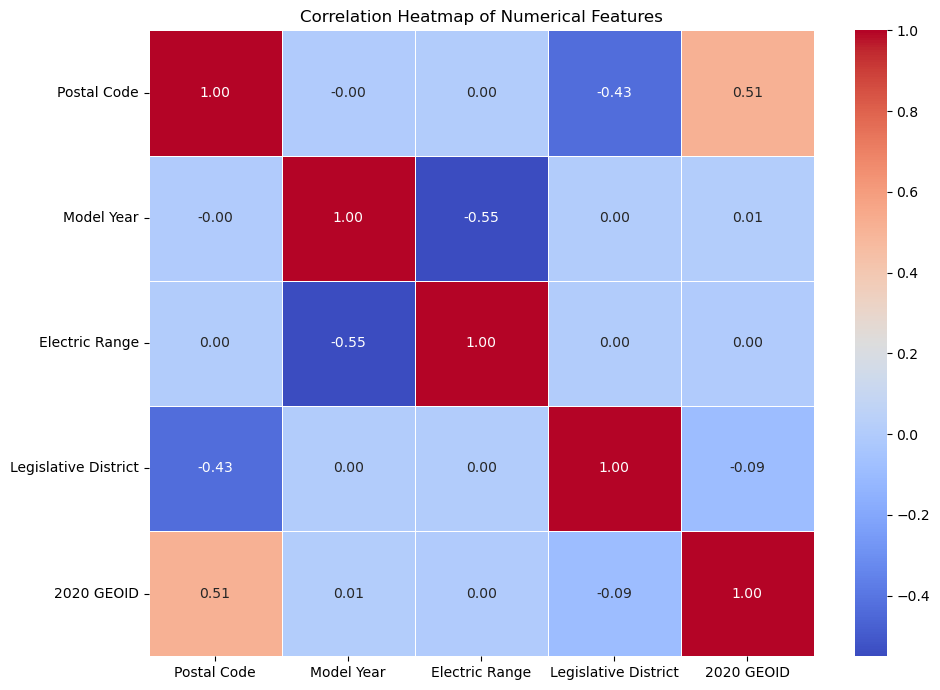

In [7]:
# Correlation heatmap for numerical features

correlation_matrix = df[numerical_features].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

Observation
The correlation heatmap shows the strength and direction of linear relationships between the numerical features.

Model Year and Electric Range show a positive relationship, indicating that newer vehicle models tend to have different electric-range characteristics. The remaining numerical features show relatively weaker relationships with each other.

No extremely strong correlation is observed among the numerical predictors,so there is no immediate indication of severe multicollinearity from this heatmap

4.4 Feature–Target Relationships
Feature–target relationships are examined to understand whether numerical vehicle characteristics differ between the two target classes.

Since Electric Vehicle Type is categorical, a temporary numerical encoding is used only for visualization:

Battery Electric Vehicle (BEV) → 0
Plug-in Hybrid Electric Vehicle (PHEV) → 1
This encoding is used only to create the scatter plots and does not represent the preprocessing used for model training.

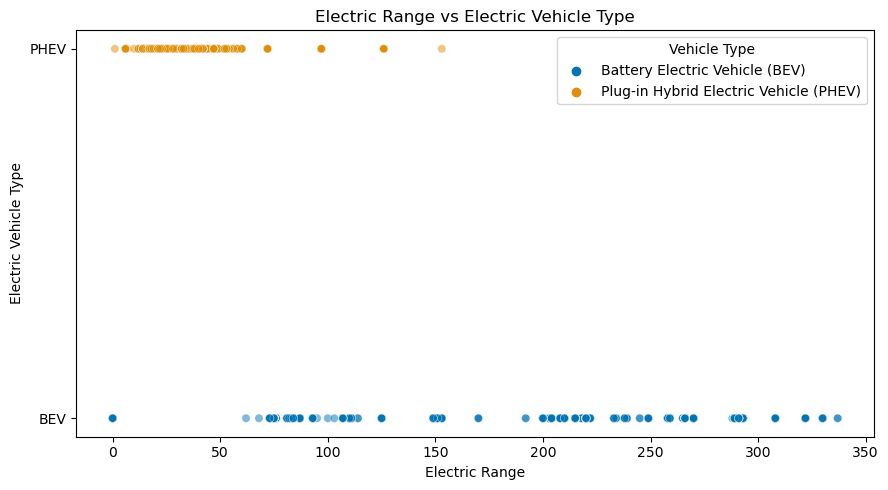

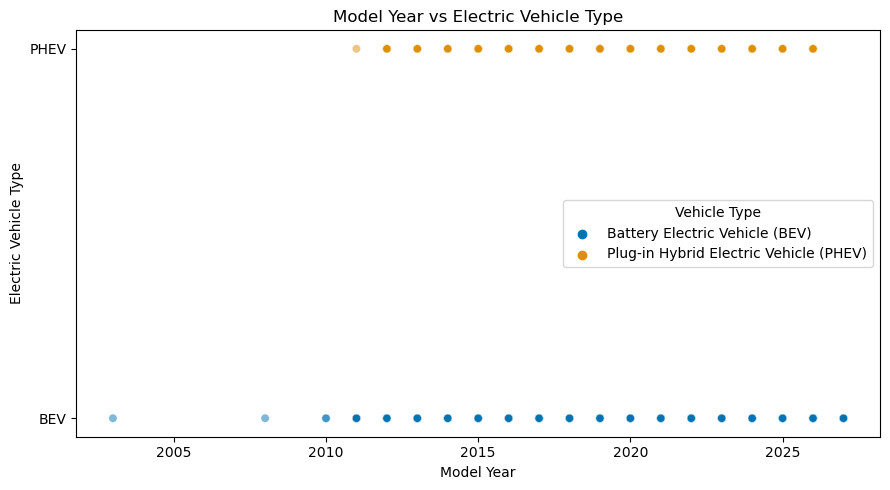

In [8]:
# Temporary target encoding for visualization only
target_numeric = {
    "Battery Electric Vehicle (BEV)": 0,
    "Plug-in Hybrid Electric Vehicle (PHEV)": 1
}

df_eda = df.copy()
df_eda["Target_Numeric"] = df_eda["Electric Vehicle Type"].map(target_numeric)

# Sample data for clearer visualization
plot_data = df_eda.sample(n=10000, random_state=42)

# Scatter Plot 1: Electric Range vs Target
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=plot_data,
    x="Electric Range",
    y="Target_Numeric",
    hue="Electric Vehicle Type",
    alpha=0.5
)

plt.title("Electric Range vs Electric Vehicle Type")
plt.xlabel("Electric Range")
plt.ylabel("Electric Vehicle Type")
plt.yticks([0, 1], ["BEV", "PHEV"])
plt.legend(title="Vehicle Type")
plt.tight_layout()
plt.show()


# Scatter Plot 2: Model Year vs Target
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=plot_data,
    x="Model Year",
    y="Target_Numeric",
    hue="Electric Vehicle Type",
    alpha=0.5
)

plt.title("Model Year vs Electric Vehicle Type")
plt.xlabel("Model Year")
plt.ylabel("Electric Vehicle Type")
plt.yticks([0, 1], ["BEV", "PHEV"])
plt.legend(title="Vehicle Type")
plt.tight_layout()
plt.show()

Observations¶
The scatter plots indicate differences in the distribution of Electric Range and Model Year between BEV and PHEV vehicles.

Electric Range shows a noticeable difference between the two vehicle types, suggesting that it may be an informative feature for classification.

Model Year also shows differences in the distribution of the two classes, indicating that vehicle age may provide useful information for predicting Electric Vehicle Type.

These observations are exploratory and will be verified quantitatively through the classification models.

4.5 EDA Insights¶
The exploratory data analysis provides the following observations:

The dataset contains both numerical and categorical features, with noticeable differences in the distributions of several vehicle characteristics.

The target variable, Electric Vehicle Type, is imbalanced, with Battery Electric Vehicles (BEVs) forming the majority class and Plug-in Hybrid Electric Vehicles (PHEVs) forming the minority class.

The correlation heatmap shows relationships among the numerical features. No extremely strong correlation is observed between the numerical predictors.

Electric Range shows differences between BEV and PHEV vehicles, making it a potentially useful feature for classification.

Model Year also shows differences between the two vehicle types,suggesting that it may contain useful information for predicting the target.

-These observations will be considered when performing data cleaning, feature engineering, preprocessing, and classification model training.

5. Data Cleaning
Before model training, the dataset is checked for missing values, duplicate records, and potential outliers.

Missing values are handled using appropriate imputation strategies rather than removing large numbers of observations. Duplicate rows are removed if present.

Outliers are examined for numerical features. Since extreme values may represent genuine vehicle characteristics rather than data-entry errors, they will be identified using the IQR method and treated only where appropriate.

In [9]:
# Create a working copy
df_clean = df.copy()

# 1. Handle missing values
numerical_cols = df_clean.select_dtypes(include=np.number).columns
categorical_cols = df_clean.select_dtypes(include="object").columns

# Numerical columns: median imputation
for column in numerical_cols:
    if df_clean[column].isnull().sum() > 0:
        df_clean[column] = df_clean[column].fillna(df_clean[column].median())

# Categorical columns: mode imputation
for column in categorical_cols:
    if df_clean[column].isnull().sum() > 0:
        df_clean[column] = df_clean[column].fillna(df_clean[column].mode()[0])

# 2. Remove duplicate rows
duplicates_before = df_clean.duplicated().sum()
df_clean = df_clean.drop_duplicates()

# 3. Check for outliers using IQR
outlier_summary = []

for column in numerical_cols:
    Q1 = df_clean[column].quantile(0.25)
    Q3 = df_clean[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = ((df_clean[column] < lower_bound) |
                (df_clean[column] > upper_bound)).sum()

    outlier_summary.append([column, outliers])

outlier_summary = pd.DataFrame(
    outlier_summary,
    columns=["Feature", "Outlier Count"]
)

print("Missing values after imputation:")
display(df_clean.isnull().sum().to_frame("Missing Count"))

print("Duplicate rows removed:", duplicates_before)

print("Outlier summary:")
display(outlier_summary)

Missing values after imputation:


,Missing Count
VIN (1-10),0
County,0
City,0
State,0
Postal Code,0
Model Year,0
Make,0
Model,0
Electric Vehicle Type,0
Clean Alternative Fuel Vehicle (CAFV) Eligibility,0


Duplicate rows removed: 0
Outlier summary:


,Feature,Outlier Count
0,Postal Code,20940
1,Model Year,18098
2,Electric Range,42798
3,Legislative District,0
4,DOL Vehicle ID,25203
5,2020 GEOID,751


Data Cleaning Observations
The missing values were handled using median imputation for numerical features and mode imputation for categorical features. This preserves the available observations while providing a simple and robust treatment for the small number of missing values.

Duplicate records were checked and removed if present.

Potential numerical outliers were identified using the IQR method. These values were retained because extreme vehicle characteristics may represent valid observations rather than data-entry errors. The outlier information will therefore be considered during subsequent preprocessing and modeling.

6.1 Feature Selection
The target variable Electric Vehicle Type is separated from the predictor variables.

Identifier columns such as VIN (1-10) and DOL Vehicle ID are excluded because they identify individual records rather than describe meaningful vehicle characteristics.

The target variable is retained separately and is not included among the predictor features.

In [12]:
# Define target
target = "Electric Vehicle Type"

# Identifier columns that should not be used as predictors
identifier_columns = [
    "VIN (1-10)",
    "DOL Vehicle ID"
]

# Separate features and target
target_proxy_columns = [
    "Clean Alternative Fuel Vehicle (CAFV) Eligibility"
]

X = df_clean.drop(
    columns=[target] + identifier_columns + target_proxy_columns
)
y = df_clean[target]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeatures used for classification:")
print(X.columns.tolist())

print("\nTarget classes:")
print(y.value_counts())

Feature shape: (294193, 12)
Target shape: (294193,)

Features used for classification:
['County', 'City', 'State', 'Postal Code', 'Model Year', 'Make', 'Model', 'Electric Range', 'Legislative District', 'Vehicle Location', 'Electric Utility', '2020 GEOID']

Target classes:
Battery Electric Vehicle (BEV)            237567
Plug-in Hybrid Electric Vehicle (PHEV)     56626
Name: Electric Vehicle Type, dtype: int64


6.2 Feature Engineering
A new feature, Vehicle Age, is created from Model Year.

The feature is calculated as:

Vehicle Age = 2026 - Model Year
Vehicle age may provide additional information about the type of electric vehicle because BEVs and PHEVs may have different adoption patterns across model years.

This engineered feature provides the classification models with an explicit measure of vehicle age rather than requiring the models to derive this relationship indirectly from the raw Model Year feature.

In [13]:
# Create engineered feature
X["Vehicle Age"] = 2026 - X["Model Year"]

# Check the new feature
display(X[["Model Year", "Vehicle Age"]].head())

print("Updated feature shape:", X.shape)

,Model Year,Vehicle Age
0,2020,6
1,2019,7
2,2015,11
3,2020,6
4,2019,7


Updated feature shape: (294193, 13)


7. Train-Test Split
The dataset is divided into training and testing sets using an 80:20 split.

Stratification is used to preserve the proportion of BEV and PHEV classes in both the training and testing sets.

A fixed random state of 42 is used to make the split reproducible.

In [14]:
from sklearn.model_selection import train_test_split

# Stratified 80:20 train-test split
X_train_1, X_test, y_train_1, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set shape:", X_train_1.shape)
print("Testing set shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train_1.value_counts(normalize=True).mul(100).round(2))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).mul(100).round(2))

Training set shape: (235354, 13)
Testing set shape: (58839, 13)

Training target distribution:
Battery Electric Vehicle (BEV)            80.75
Plug-in Hybrid Electric Vehicle (PHEV)    19.25
Name: Electric Vehicle Type, dtype: float64

Testing target distribution:
Battery Electric Vehicle (BEV)            80.75
Plug-in Hybrid Electric Vehicle (PHEV)    19.25
Name: Electric Vehicle Type, dtype: float64


In [15]:
# Create a stratified 60,000-sample subset from the training data

X_train, _, y_train, _ = train_test_split(
    X_train_1,
    y_train_1,
    train_size=60000,
    random_state=42,
    stratify=y_train_1
)

print("Original training set:", X_train_1.shape)
print("60K training subset  :", X_train.shape)

print("\nOriginal training class distribution:")
print(y_train_1.value_counts(normalize=True).mul(100).round(2))

print("\n60K training class distribution:")
print(y_train.value_counts(normalize=True).mul(100).round(2))

Original training set: (235354, 13)
60K training subset  : (60000, 13)

Original training class distribution:
Battery Electric Vehicle (BEV)            80.75
Plug-in Hybrid Electric Vehicle (PHEV)    19.25
Name: Electric Vehicle Type, dtype: float64

60K training class distribution:
Battery Electric Vehicle (BEV)            80.75
Plug-in Hybrid Electric Vehicle (PHEV)    19.25
Name: Electric Vehicle Type, dtype: float64


Observation
The dataset was divided into training and testing sets using an 80:20 split. Stratification preserves approximately the same BEV-to-PHEV class proportion in both sets.

The training set will be used to fit the preprocessing steps and classification models, while the test set will be kept separate for final model evaluation

8. Encoding & Feature Scaling
Categorical features are converted into numerical representations using One-Hot Encoding, while numerical features are standardized using StandardScaler.

The preprocessing transformations are fitted only on the training data.The same fitted transformations are then applied to the test data. This prevents information from the test set from leaking into the training process.

In [16]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

# Identify numerical and categorical features
numerical_features_model = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features_model = X_train.select_dtypes(
    include="object"
).columns.tolist()

print("Numerical features:")
print(numerical_features_model)

print("\nCategorical features:")
print(categorical_features_model)

# Create preprocessing transformer
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features_model),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features_model)
    ]
)

# Fit ONLY on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform test data using the same fitted transformer
X_test_processed = preprocessor.transform(X_test)

print("\nProcessed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Numerical features:
['Postal Code', 'Model Year', 'Electric Range', 'Legislative District', '2020 GEOID', 'Vehicle Age']

Categorical features:
['County', 'City', 'State', 'Make', 'Model', 'Vehicle Location', 'Electric Utility']

Processed training shape: (60000, 1694)
Processed testing shape: (58839, 1694)


9. Logistic Regression
Logistic Regression is used as the baseline classification model.

It estimates the probability that a vehicle belongs to a particular vehicle type. Since the target contains two classes, the model predicts whether a vehicle is a Battery Electric Vehicle (BEV) or a Plug-in Hybrid Electric Vehicle (PHEV).

The model will be evaluated using Accuracy, Precision, Recall, weighted F1-score, and a Confusion Matrix.

Logistic Regression Results
---------------------------
Accuracy : 0.9933
Precision: 0.9933
Recall   : 0.9933
Weighted F1: 0.9933


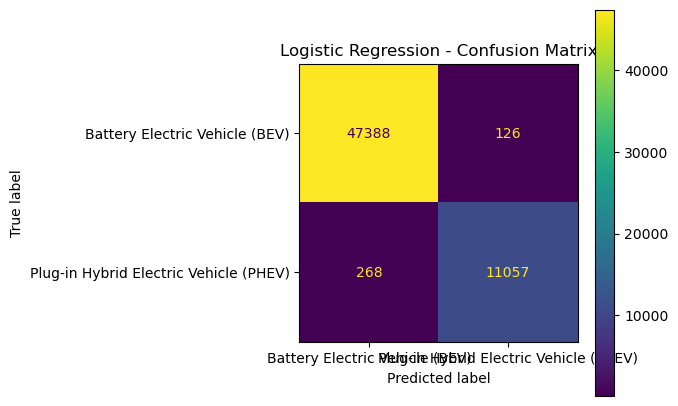

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Train Logistic Regression
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train_processed, y_train)

# Predictions
y_pred_logistic = logistic_model.predict(X_test_processed)

# Evaluation metrics
logistic_accuracy = accuracy_score(y_test, y_pred_logistic)
logistic_precision = precision_score(
    y_test, y_pred_logistic, average="weighted"
)
logistic_recall = recall_score(
    y_test, y_pred_logistic, average="weighted"
)
logistic_f1 = f1_score(
    y_test, y_pred_logistic, average="weighted"
)

print("Logistic Regression Results")
print("---------------------------")
print("Accuracy :", round(logistic_accuracy, 4))
print("Precision:", round(logistic_precision, 4))
print("Recall   :", round(logistic_recall, 4))
print("Weighted F1:", round(logistic_f1, 4))

# Confusion Matrix
cm_logistic = confusion_matrix(y_test, y_pred_logistic)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_logistic,
    display_labels=logistic_model.classes_
)

disp.plot()
plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()

In [18]:
# Get feature names after preprocessing
feature_names = preprocessor.get_feature_names_out()

# Get Logistic Regression coefficients
coefficients = logistic_model.coef_[0]

# Create coefficient table
coefficient_table = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients,
    "Odds Ratio": np.exp(coefficients)
})

# Largest positive coefficients
print("Top 10 positive coefficients:")
display(
    coefficient_table
    .sort_values("Coefficient", ascending=False)
    .head(10)
)

# Largest negative coefficients
print("Top 10 negative coefficients:")
display(
    coefficient_table
    .sort_values("Coefficient", ascending=True)
    .head(10)
)

Top 10 positive coefficients:


,Feature,Coefficient,Odds Ratio
942,cat__Model_VOLT,7.132229,1251.663483
907,cat__Model_RAV4 PRIME (PHEV),6.223498,504.464818
897,cat__Model_Q5 E,5.743614,312.190654
928,cat__Model_SPORTAGE,5.703009,299.767933
825,cat__Model_ESCAPE,5.662700,287.924917
936,cat__Model_TUCSON,5.513702,248.067695
892,cat__Model_PRIUS PRIME (PHEV),5.473597,238.315798
949,cat__Model_XC90,5.035057,153.708308
924,cat__Model_SORENTO,5.030252,152.971514
948,cat__Model_XC60,4.951124,141.333759


Top 10 negative coefficients:


,Feature,Coefficient,Odds Ratio
763,cat__Make_TESLA,-5.318202,0.004902
854,cat__Model_I4,-5.134880,0.005888
865,cat__Model_IX,-4.851572,0.007816
827,cat__Model_EV6,-4.493824,0.011178
913,cat__Model_RZ,-4.467427,0.011477
947,cat__Model_XC40,-4.332893,0.013130
877,cat__Model_MUSTANG MACH-E,-4.238311,0.014432
861,cat__Model_IONIQ 5,-4.147585,0.015803
793,cat__Model_BZ4X,-3.874385,0.020767
868,cat__Model_LEAF,-3.825286,0.021812


##Observation

Logistic Regression provides a baseline for comparing the classification
models in Part A.

The Accuracy, Precision, Recall, and weighted F1-score provide quantitative
measures of classification performance, while the confusion matrix shows
the number of correctly and incorrectly classified BEV and PHEV vehicles.

The coefficient analysis identifies the encoded features that have the
strongest positive and negative associations with the model's predicted
class. The corresponding odds ratios provide an interpretable measure of
the effect of these coefficients.

## 10. K-Nearest Neighbors (KNN)

K-Nearest Neighbors (KNN) is a distance-based classification algorithm. For a new observation, it identifies the k closest training observations and assigns the class that is most common among those neighbors.

The main hyperparameter is k, which determines the number of neighboring observations considered during prediction.

- A small k can make the model sensitive to individual observations and noise.
- A large k produces smoother predictions but may reduce sensitivity to local patterns.

Since KNN relies on distances, feature scaling is important. Numerical features were standardized using StandardScaler, while categorical features were converted into numerical representations using OneHotEncoder.

For this dataset, Euclidean distance is used as the default distance metric. Different values of k are evaluated to identify a suitable value before training the final KNN model.

In [20]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score

# Create a manageable stratified subset for KNN tuning
X_knn_tune, _, y_knn_tune, _ = train_test_split(
    X_train_processed,
    y_train,
    train_size=30000,
    random_state=42,
    stratify=y_train
)

# Split the tuning subset into training and validation data
X_knn_subtrain, X_knn_val, y_knn_subtrain, y_knn_val = train_test_split(
    X_knn_tune,
    y_knn_tune,
    test_size=0.20,
    random_state=42,
    stratify=y_knn_tune
)

k_values = [3, 5, 7, 9, 11]
knn_tuning_results = []

for k in k_values:
    knn = KNeighborsClassifier(
        n_neighbors=k,
        metric="euclidean",
        n_jobs=-1
    )

    knn.fit(X_knn_subtrain, y_knn_subtrain)

    y_pred_val = knn.predict(X_knn_val)

    accuracy = accuracy_score(y_knn_val, y_pred_val)
    weighted_f1 = f1_score(
        y_knn_val,
        y_pred_val,
        average="weighted"
    )

    knn_tuning_results.append([
        k,
        accuracy,
        weighted_f1
    ])

knn_tuning_results = pd.DataFrame(
    knn_tuning_results,
    columns=["k", "Accuracy", "Weighted F1"]
)

display(knn_tuning_results)

,k,Accuracy,Weighted F1
0,3,0.962167,0.961567
1,5,0.957333,0.956194
2,7,0.956167,0.954759
3,9,0.951000,0.949090
4,11,0.948333,0.945825


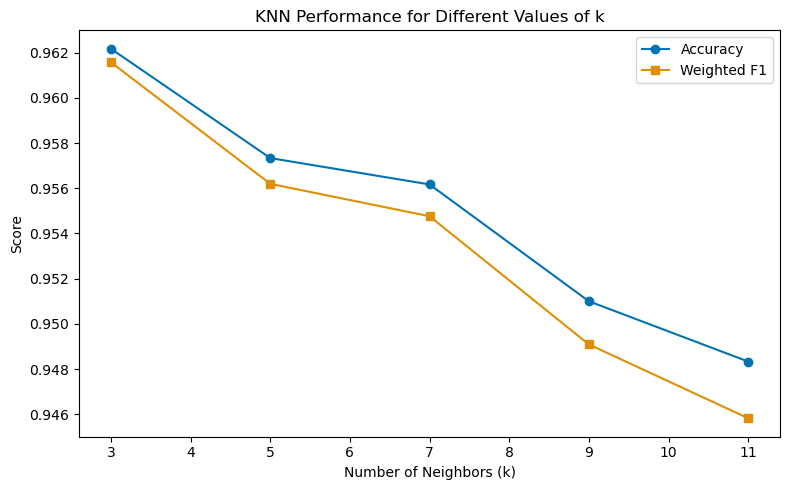

In [21]:
plt.figure(figsize=(8,5))

plt.plot(
    knn_tuning_results["k"],
    knn_tuning_results["Accuracy"],
    marker="o",
    label="Accuracy"
)

plt.plot(
    knn_tuning_results["k"],
    knn_tuning_results["Weighted F1"],
    marker="s",
    label="Weighted F1"
)

plt.title("KNN Performance for Different Values of k")
plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Score")
plt.legend()
plt.tight_layout()
plt.show()

In [22]:
best_k = int(
    knn_tuning_results.loc[
        knn_tuning_results["Weighted F1"].idxmax(),
        "k"
    ]
)

print("Best k:", best_k)

Best k: 3


Distance Metric
KNN requires a distance metric to determine which observations are closest to a new observation.

This implementation uses Euclidean distance, which is the standard distance metric for continuous, scaled numerical feature representations. Since the numerical features have been standardized, differences in their original scales do not dominate the distance calculation.

The categorical variables were one-hot encoded before applying KNN, allowing them to participate in the distance calculation numerically.

Euclidean distance is used consistently during the k-tuning process so that the effect of k can be evaluated independently of changes in the distance metri

KNN Results
-----------
Best k    : 3
Metric    : Euclidean
Accuracy  : 0.9725
Precision : 0.9722
Recall    : 0.9725
Weighted F1: 0.9723


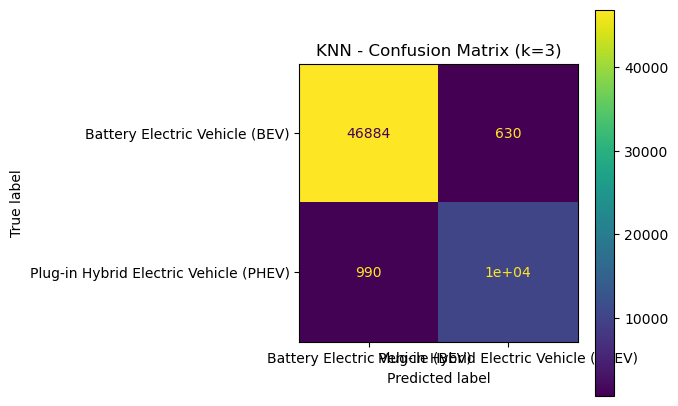

In [23]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Final KNN model
knn_final = KNeighborsClassifier(
    n_neighbors=3,
    metric="euclidean",
    n_jobs=-1
)

# Train using PROCESSED data
knn_final.fit(X_train_processed, y_train)

# Predictions
y_pred_knn = knn_final.predict(X_test_processed)

# Evaluation metrics
knn_accuracy = accuracy_score(y_test, y_pred_knn)

knn_precision = precision_score(
    y_test,
    y_pred_knn,
    average="weighted"
)

knn_recall = recall_score(
    y_test,
    y_pred_knn,
    average="weighted"
)

knn_f1 = f1_score(
    y_test,
    y_pred_knn,
    average="weighted"
)

print("KNN Results")
print("-----------")
print("Best k    :", 3)
print("Metric    : Euclidean")
print("Accuracy  :", round(knn_accuracy, 4))
print("Precision :", round(knn_precision, 4))
print("Recall    :", round(knn_recall, 4))
print("Weighted F1:", round(knn_f1, 4))

# Confusion Matrix
cm_knn = confusion_matrix(y_test, y_pred_knn)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_knn,
    display_labels=knn_final.classes_
)

disp.plot()
plt.title("KNN - Confusion Matrix (k=3)")
plt.tight_layout()
plt.show()

11. Gaussian Naive Bayes
Gaussian Naive Bayes is a probabilistic classification algorithm based on Bayes' theorem.

It assumes that the features are conditionally independent given the target class. For numerical features, Gaussian Naive Bayes assumes that the feature values within each class follow a Gaussian (normal) distribution.

The model is trained on the same preprocessed training data used by the other Part-A classifiers and evaluated on the same held-out test set.

The model is evaluated using Accuracy, Precision, Recall, Weighted F1-score, and a Confusion Matrix.

Gaussian Naive Bayes Results
----------------------------
Accuracy  : 0.9867
Precision : 0.9874
Recall    : 0.9867
Weighted F1: 0.9868


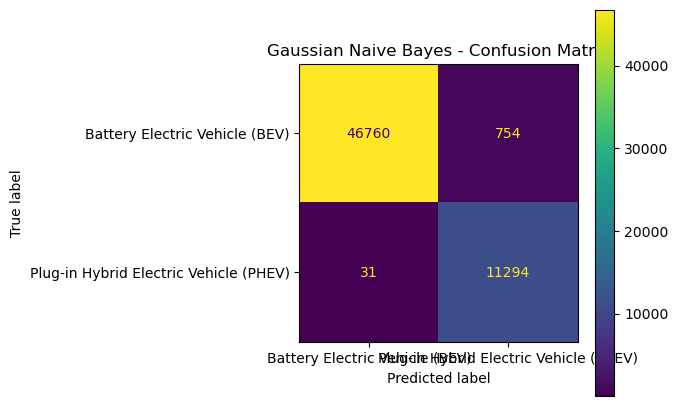

In [24]:
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Gaussian Naive Bayes
nb_model = GaussianNB()

# GaussianNB requires dense input
X_train_nb = X_train_processed.toarray()
X_test_nb = X_test_processed.toarray()

# Train the model
nb_model.fit(X_train_nb, y_train)

# Predictions
y_pred_nb = nb_model.predict(X_test_nb)

# Evaluation metrics
nb_accuracy = accuracy_score(y_test, y_pred_nb)

nb_precision = precision_score(
    y_test,
    y_pred_nb,
    average="weighted"
)

nb_recall = recall_score(
    y_test,
    y_pred_nb,
    average="weighted"
)

nb_f1 = f1_score(
    y_test,
    y_pred_nb,
    average="weighted"
)

print("Gaussian Naive Bayes Results")
print("----------------------------")
print("Accuracy  :", round(nb_accuracy, 4))
print("Precision :", round(nb_precision, 4))
print("Recall    :", round(nb_recall, 4))
print("Weighted F1:", round(nb_f1, 4))

# Confusion Matrix
cm_nb = confusion_matrix(y_test, y_pred_nb)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_nb,
    display_labels=nb_model.classes_
)

disp.plot()
plt.title("Gaussian Naive Bayes - Confusion Matrix")
plt.tight_layout()
plt.show()

Step 12: Decision Tree Classifier
A Decision Tree Classifier recursively splits the data based on feature values to form a tree structure for classification.

The max_depth parameter is tuned using a stratified validation subset created only from the 60,000 training samples. The best depth is selected based on weighted F1 score.

After selecting the best depth, the final Decision Tree is trained using all 60,000 training samples and evaluated on the unchanged test set.

In [25]:
from sklearn.tree import DecisionTreeClassifier

# Create validation split only from the 60K training data
X_dt_train, X_dt_val, y_dt_train, y_dt_val = train_test_split(
    X_train_processed,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

max_depth_values = [3, 5, 7, 10, 15, 20]

tree_tuning_results = []

for depth in max_depth_values:

    tree_model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    tree_model.fit(X_dt_train, y_dt_train)

    y_val_pred = tree_model.predict(X_dt_val)

    val_f1 = f1_score(
        y_dt_val,
        y_val_pred,
        average="weighted"
    )

    tree_tuning_results.append({
        "max_depth": depth,
        "Weighted F1": val_f1
    })

tree_tuning_results = pd.DataFrame(tree_tuning_results)

print(tree_tuning_results)

best_depth = int(
    tree_tuning_results.loc[
        tree_tuning_results["Weighted F1"].idxmax(),
        "max_depth"
    ]
)

print("\nBest max_depth:", best_depth)

   max_depth  Weighted F1
0          3     0.998170
1          5     0.999833
2          7     1.000000
3         10     1.000000
4         15     1.000000
5         20     1.000000

Best max_depth: 7


Decision Tree Results
---------------------
Best max_depth: 7
Accuracy  : 0.9999
Precision : 0.9999
Recall    : 0.9999
Weighted F1: 0.9999


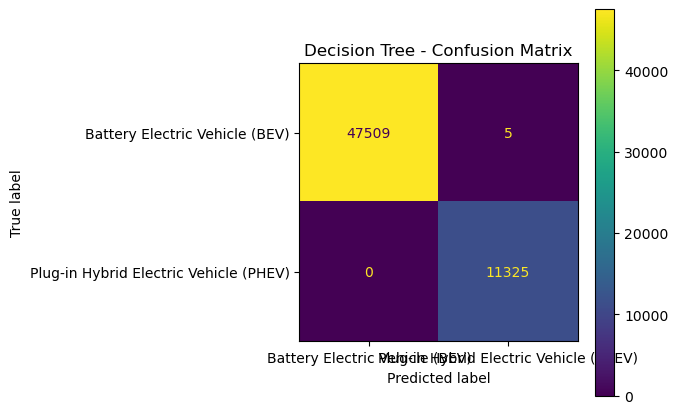

In [26]:
# Train final Decision Tree using all 60K training samples

tree_final = DecisionTreeClassifier(
    max_depth=best_depth,
    random_state=42
)

tree_final.fit(X_train_processed, y_train)

y_pred_tree = tree_final.predict(X_test_processed)

# Metrics
tree_accuracy = accuracy_score(y_test, y_pred_tree)
tree_precision = precision_score(
    y_test,
    y_pred_tree,
    average="weighted"
)
tree_recall = recall_score(
    y_test,
    y_pred_tree,
    average="weighted"
)
tree_f1 = f1_score(
    y_test,
    y_pred_tree,
    average="weighted"
)

print("Decision Tree Results")
print("---------------------")
print("Best max_depth:", best_depth)
print("Accuracy  :", round(tree_accuracy, 4))
print("Precision :", round(tree_precision, 4))
print("Recall    :", round(tree_recall, 4))
print("Weighted F1:", round(tree_f1, 4))

# Confusion Matrix
cm_tree = confusion_matrix(y_test, y_pred_tree)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_tree,
    display_labels=tree_final.classes_
)

disp.plot()
plt.title("Decision Tree - Confusion Matrix")
plt.tight_layout()
plt.show()

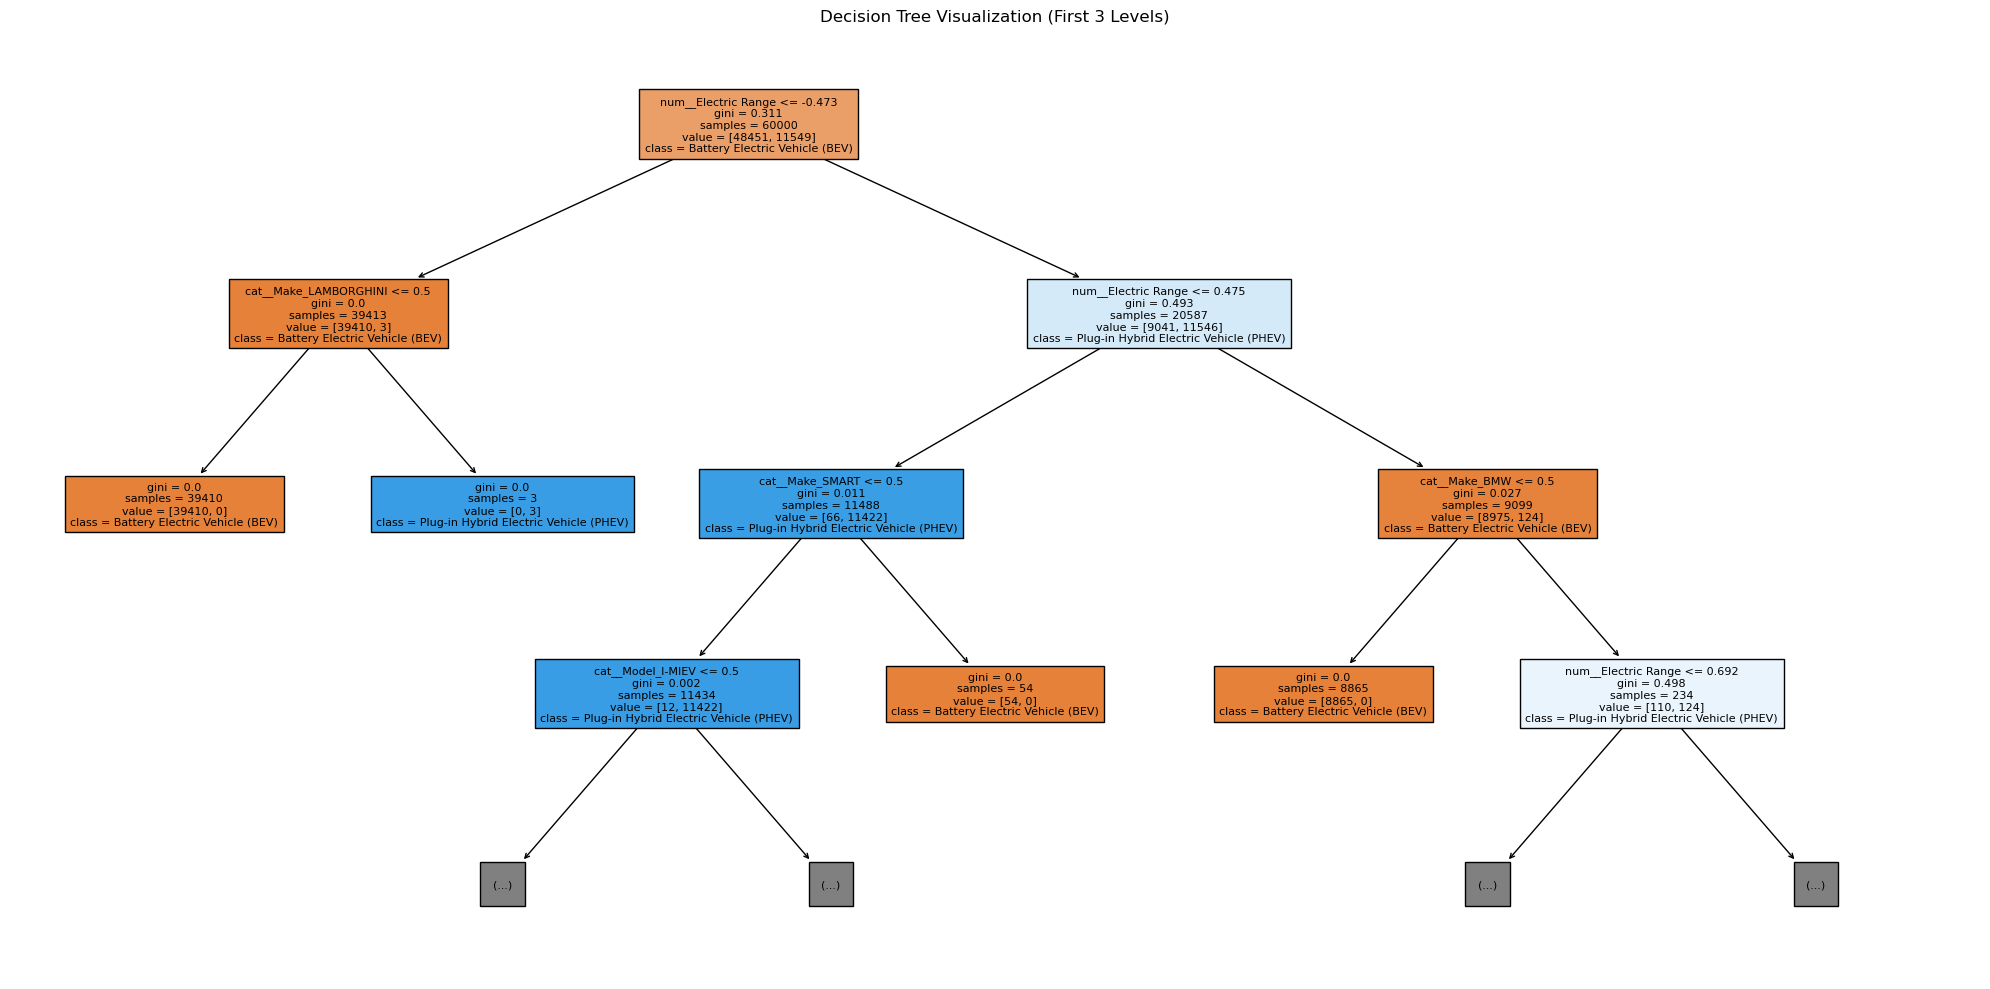

In [27]:
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))

plot_tree(
    tree_final,
    max_depth=3,
    feature_names=feature_names,
    class_names=[str(c) for c in tree_final.classes_],
    filled=True,
    fontsize=8
)

plt.title("Decision Tree Visualization (First 3 Levels)")
plt.tight_layout()
plt.show()

Step 13: Support Vector Machine
Support Vector Machine (SVM) is a classification algorithm that finds a decision boundary that separates different classes.

The regularization parameter C and kernel type are tuned using a stratified subset of the 60,000 training samples. The selected parameters are then used for the final SVC model.

The same preprocessed training and held-out test data are used for evaluation. Since SVM training can be computationally expensive for large datasets, the tuning stage uses a smaller stratified subset while preserving the original class distribution.